 # Get the data

In [1]:
from pathlib import Path
input_dir = Path("/kaggle/input")
for folder in input_dir.iterdir():
    print(folder)

/kaggle/input/datasets


In [2]:
data_dir = input_dir / "datasets"

for folder in data_dir.iterdir():
    print(folder)

/kaggle/input/datasets/paultimothymooney


In [3]:
for folder in data_dir.rglob("*"):
    if folder.is_dir() and folder.name in ["train", "val", "test"]:
        print(folder)

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/val
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/test
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/train
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/val
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train
/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val


In [4]:
dataset_dir = (
    data_dir/"paultimothymooney"/"chest-xray-pneumonia"/"chest_xray"
)

train_dir = dataset_dir / "train"
val_dir = dataset_dir / "val"
test_dir = dataset_dir / "test"

In [5]:
for split_dir in [train_dir, val_dir, test_dir]:
    print(f"\n{split_dir.name.upper()}")

    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_dir = split_dir / class_name

        image_count = sum(
            1 for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        )

        print(f"{class_name}: {image_count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


# Import Libraries

In [6]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Visualize training images

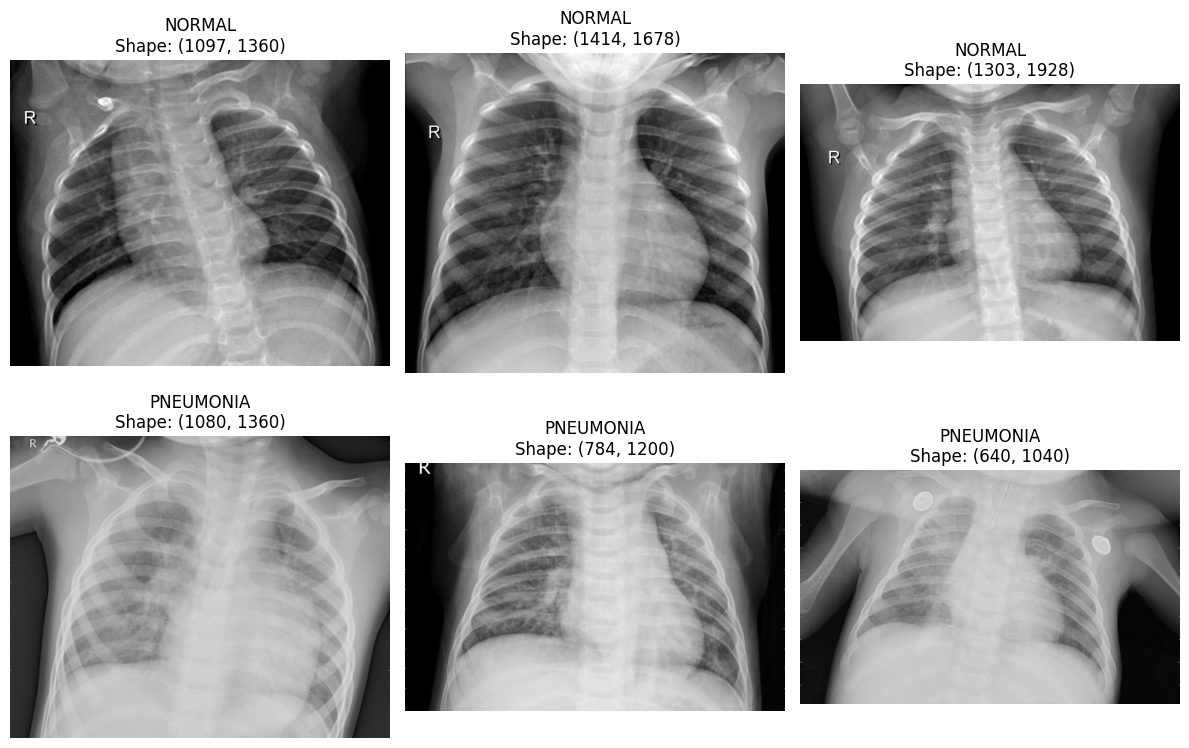

In [7]:
import random

random.seed(42)
class_names = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(12, 8))

for row, class_name in enumerate(class_names):
    image_paths = [
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    selected_images = random.sample(sorted(image_paths), 3)

    for col, image_path in enumerate(selected_images):
        image = plt.imread(image_path)

        plt.subplot(2, 3, row * 3 + col + 1)
        plt.imshow(image, cmap="gray")
        plt.title(f"{class_name}\nShape: {image.shape}")
        plt.axis("off")

plt.tight_layout()
plt.show()

## prepare_training_and_validation_data

In [8]:
class_names = ["NORMAL", "PNEUMONIA"]
for class_name in class_names:
    print(f"\n{class_name} filenames:")

    image_paths = sorted(
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    for image_path in image_paths[:5]:
        print(image_path.name)


NORMAL filenames:
IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg

PNEUMONIA filenames:
person1000_bacteria_2931.jpeg
person1000_virus_1681.jpeg
person1001_bacteria_2932.jpeg
person1002_bacteria_2933.jpeg
person1003_bacteria_2934.jpeg


In [9]:
import pandas as pd

records = []

for class_name in class_names:
    for image_path in sorted((train_dir / class_name).iterdir()):
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            records.append({
                "filepath": str(image_path),
                "filename": image_path.name,
                "class_name": class_name,
                "label": class_names.index(class_name)
            })

image_df = pd.DataFrame(records)

display(image_df.head())
print("\nClass counts:")
print(image_df["class_name"].value_counts())

,filepath,filename,class_name,label
0,/kaggle/input/datasets/paultimothymooney/chest...,IM-0115-0001.jpeg,NORMAL,0
1,/kaggle/input/datasets/paultimothymooney/chest...,IM-0117-0001.jpeg,NORMAL,0
2,/kaggle/input/datasets/paultimothymooney/chest...,IM-0119-0001.jpeg,NORMAL,0
3,/kaggle/input/datasets/paultimothymooney/chest...,IM-0122-0001.jpeg,NORMAL,0
4,/kaggle/input/datasets/paultimothymooney/chest...,IM-0125-0001.jpeg,NORMAL,0



Class counts:
class_name
PNEUMONIA    3875
NORMAL       1341
Name: count, dtype: int64


In [10]:
normal_names = image_df.loc[
    image_df["class_name"] == "NORMAL", "filename"
]

print(normal_names.sample(15, random_state=42).to_string(index=False))

NORMAL2-IM-0657-0001.jpeg
        IM-0701-0001.jpeg
        IM-0728-0001.jpeg
        IM-0606-0001.jpeg
        IM-0459-0001.jpeg
   IM-0501-0001-0002.jpeg
NORMAL2-IM-1102-0001.jpeg
        IM-0658-0001.jpeg
NORMAL2-IM-0840-0001.jpeg
NORMAL2-IM-0531-0001.jpeg
NORMAL2-IM-1017-0001.jpeg
NORMAL2-IM-1120-0001.jpeg
        IM-0240-0001.jpeg
        IM-0466-0001.jpeg
NORMAL2-IM-1104-0001.jpeg


In [11]:
image_df

,filepath,filename,class_name,label
0,/kaggle/input/datasets/paultimothymooney/chest...,IM-0115-0001.jpeg,NORMAL,0
1,/kaggle/input/datasets/paultimothymooney/chest...,IM-0117-0001.jpeg,NORMAL,0
2,/kaggle/input/datasets/paultimothymooney/chest...,IM-0119-0001.jpeg,NORMAL,0
3,/kaggle/input/datasets/paultimothymooney/chest...,IM-0122-0001.jpeg,NORMAL,0
4,/kaggle/input/datasets/paultimothymooney/chest...,IM-0125-0001.jpeg,NORMAL,0
...,...,...,...,...
5211,/kaggle/input/datasets/paultimothymooney/chest...,person99_virus_183.jpeg,PNEUMONIA,1
5212,/kaggle/input/datasets/paultimothymooney/chest...,person9_bacteria_38.jpeg,PNEUMONIA,1
5213,/kaggle/input/datasets/paultimothymooney/chest...,person9_bacteria_39.jpeg,PNEUMONIA,1
5214,/kaggle/input/datasets/paultimothymooney/chest...,person9_bacteria_40.jpeg,PNEUMONIA,1


In [12]:
def get_image_group(filename):
    if filename.startswith("person"):
        return filename.split("_")[0]

    if filename.startswith("NORMAL2-IM-"):
        return "-".join(filename.split("-")[:3])

    if filename.startswith("IM-"):
        return "-".join(filename.split("-")[:2])

    raise ValueError(f"Unrecognized filename: {filename}")


image_df["group_id"] = image_df["filename"].apply(get_image_group)

display(
    image_df[["filename", "class_name", "group_id"]]
    .sample(10, random_state=42)
)

print("Total images:", len(image_df))
print("Unique groups:", image_df["group_id"].nunique())

,filename,class_name,group_id
1897,person1288_virus_2211.jpeg,PNEUMONIA,person1288
877,NORMAL2-IM-0816-0001.jpeg,NORMAL,NORMAL2-IM-0816
4503,person61_bacteria_290.jpeg,PNEUMONIA,person61
4725,person722_virus_1341.jpeg,PNEUMONIA,person722
1595,person1141_virus_1890.jpeg,PNEUMONIA,person1141
4709,person716_bacteria_2617.jpeg,PNEUMONIA,person716
893,NORMAL2-IM-0832-0001-0002.jpeg,NORMAL,NORMAL2-IM-0832
1292,NORMAL2-IM-1317-0001.jpeg,NORMAL,NORMAL2-IM-1317
1168,NORMAL2-IM-1164-0001.jpeg,NORMAL,NORMAL2-IM-1164
1144,NORMAL2-IM-1142-0001-0002.jpeg,NORMAL,NORMAL2-IM-1142


Total images: 5216
Unique groups: 2846


### Split training and validation by image groups

In [13]:
from sklearn.model_selection import train_test_split
group_df = image_df[['group_id' , 'label']].drop_duplicates()
train_groups , val_groups = train_test_split(group_df , test_size = 0.2 , random_state = 42 , stratify = group_df['label'])
train_df = image_df[image_df['group_id'].isin(train_groups['group_id'])].reset_index(drop = True)
val_df = image_df[ image_df["group_id"].isin(val_groups["group_id"])
].reset_index(drop=True)
overlap = set(train_df["group_id"]) & set(val_df["group_id"])
len(train_df) , len(val_df) , len(overlap) , train_df['class_name'].value_counts(),val_df['class_name'].value_counts()


(4198,
 1018,
 0,
 class_name
 PNEUMONIA    3121
 NORMAL       1077
 Name: count, dtype: int64,
 class_name
 PNEUMONIA    754
 NORMAL       264
 Name: count, dtype: int64)

## load_and_preprocess_images

In [14]:
import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

def load_and_preprocess(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    label = tf.cast(label, tf.float32)
    label = tf.reshape(label, [1])

    return image, label

In [15]:
def make_dataset(dataframe, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["filepath"].to_numpy(),
        dataframe["label"].to_numpy()
    ))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

In [16]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("First five labels:", labels[:5].numpy().ravel())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First five labels: [1. 1. 0. 0. 1.]


# Make the model

In [17]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(
        filters=16,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │     6,422,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,423,041 (24.50 MB)

 Trainable params: 6,423,041 (24.50 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [19]:
early_stopping_1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping_1]
)

Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 65s 458ms/step - accuracy: 0.7904 - loss: 0.5325 - precision: 0.8113 - recall: 0.9356 - val_accuracy: 0.8733 - val_loss: 0.3351 - val_precision: 0.9921 - val_recall: 0.8355
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.9471 - loss: 0.1391 - precision: 0.9586 - recall: 0.9708 - val_accuracy: 0.8291 - val_loss: 0.4196 - val_precision: 0.8132 - val_recall: 0.9987
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.9659 - loss: 0.0926 - precision: 0.9754 - recall: 0.9789 - val_accuracy: 0.9528 - val_loss: 0.1085 - val_precision: 0.9916 - val_recall: 0.9443
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.9747 - loss: 0.0678 - precision: 0.9836 - recall: 0.9824 - val_accuracy: 0.9637 - val_loss: 0.0990 - val_precision: 0.9579 - val_recall: 0.9947
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.9855 - loss: 0.0470 - precision: 0.9891 - recall: 0.9913 - val_accuracy: 0.9676

In [20]:
results_1 = model.evaluate(
    val_ds,
    return_dict=True
)

print("\nModel 1 validation results:")

for metric, value in results_1.items():
    print(f"{metric}: {value:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.9695 - loss: 0.0782 - precision: 0.9788 - recall: 0.9801

Model 1 validation results:
accuracy: 0.9695
loss: 0.0782
precision: 0.9788
recall: 0.9801


In [21]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape = (224 , 224, 3)) , 
    tf.keras.layers.Conv2D(
        filters = 16 , 
        kernel_size = 3,
        activation = 'relu',
        padding = 'same'
    ),
    tf.keras.layers.MaxPooling2D(pool_size = 2),
    tf.keras.layers.Conv2D(
        filters = 32,
        kernel_size = 3,
        activation = 'relu',
        padding = 'same'
    ),
    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32 , activation = 'relu'),
    tf.keras.layers.Dense(1 , activation = 'sigmoid')
])
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │     3,211,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,225,665 (12.30 MB)

 Trainable params: 3,225,665 (12.30 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [23]:
early_stopping_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping_2]
)

Epoch 1/10


E0000 00:00:1794678940.406691     141 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794678940.806733     141 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8446 - loss: 0.4676 - precision: 0.8716 - recall: 0.9368

E0000 00:00:1794678956.085843     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


132/132 ━━━━━━━━━━━━━━━━━━━━ 26s 149ms/step - accuracy: 0.9054 - loss: 0.2476 - precision: 0.9230 - recall: 0.9523 - val_accuracy: 0.9450 - val_loss: 0.1588 - val_precision: 0.9915 - val_recall: 0.9337
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.9700 - loss: 0.0816 - precision: 0.9780 - recall: 0.9817 - val_accuracy: 0.9637 - val_loss: 0.0997 - val_precision: 0.9686 - val_recall: 0.9828
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.9783 - loss: 0.0599 - precision: 0.9853 - recall: 0.9856 - val_accuracy: 0.8900 - val_loss: 0.3541 - val_precision: 0.9984 - val_recall: 0.8528
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.9814 - loss: 0.0572 - precision: 0.9875 - recall: 0.9875 - val_accuracy: 0.9735 - val_loss: 0.0929 - val_precision: 0.9866 - val_recall: 0.9775
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.9867 - loss: 0.0363 - precision: 0.9913 - recall: 0.9907 - val_accuracy: 0.9735 - val_loss

In [24]:
result_2 = model2.evaluate(val_ds , return_dict = True)
comparison = pd.DataFrame(
    [results_1 , result_2],
    index = ['Model_1' , 'Model2']
)
comparison

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - accuracy: 0.9735 - loss: 0.0929 - precision: 0.9866 - recall: 0.9775


,accuracy,loss,precision,recall
Model_1,0.969548,0.078216,0.978808,0.980106
Model2,0.973477,0.092883,0.986613,0.977454


### Compare training and validation curves

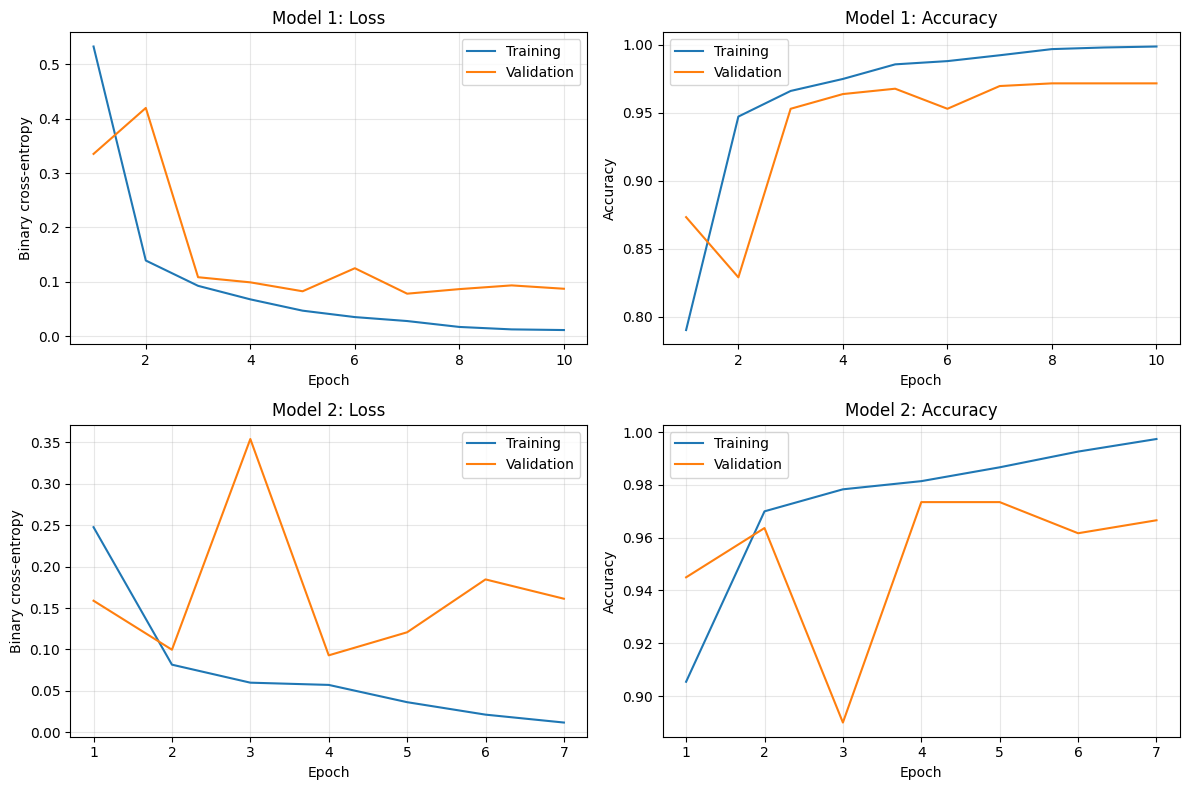

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (history, name) in enumerate([
    (history_1, "Model 1"),
    (history_2, "Model 2")
]):
    epochs = range(1, len(history.history["loss"]) + 1)

    axes[row, 0].plot(
        epochs, history.history["loss"], label="Training"
    )
    axes[row, 0].plot(
        epochs, history.history["val_loss"], label="Validation"
    )
    axes[row, 0].set_title(f"{name}: Loss")
    axes[row, 0].set_ylabel("Binary cross-entropy")

    axes[row, 1].plot(
        epochs, history.history["accuracy"], label="Training"
    )
    axes[row, 1].plot(
        epochs, history.history["val_accuracy"], label="Validation"
    )
    axes[row, 1].set_title(f"{name}: Accuracy")
    axes[row, 1].set_ylabel("Accuracy")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Model 3: Two convolution blocks with data augmentation

In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(factor=0.02),
    tf.keras.layers.RandomTranslation(
        height_factor=0.02,
        width_factor=0.02
    )
], name="data_augmentation")

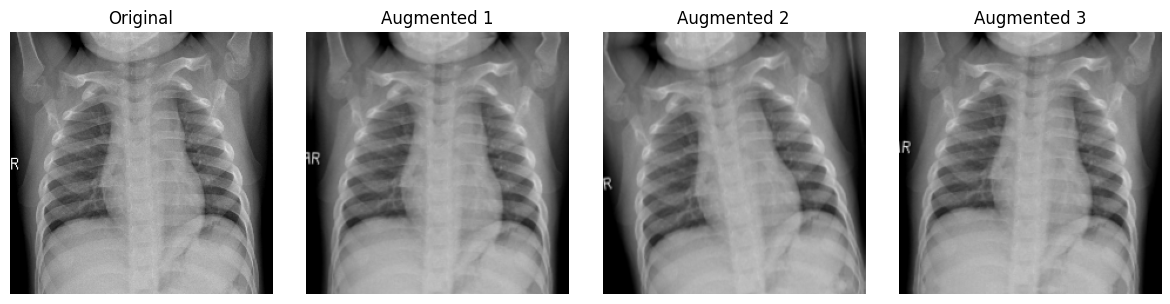

In [27]:
for images, labels in train_ds.take(1):
    example = images[:1]

plt.figure(figsize=(12, 3))

for i in range(4):
    plt.subplot(1, 4, i + 1)

    if i == 0:
        displayed_image = example[0]
        plt.title("Original")
    else:
        displayed_image = data_augmentation(
            example, training=True
        )[0]
        plt.title(f"Augmented {i}")

    plt.imshow(
        tf.clip_by_value(displayed_image, 0.0, 1.0).numpy()
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
model_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(
        filters=16,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │     3,211,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,216,417 (12.27 MB)

 Trainable params: 3,216,417 (12.27 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
early_stopping_3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_3 = model_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping_3]
)

Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.7564 - loss: 0.5031 - precision: 0.7669 - recall: 0.9462

In [ ]:
results_3 = model_3.evaluate(val_ds, return_dict=True)

comparison = pd.DataFrame(
    [results_1, result_2, results_3],
    index=[
        "Model 1: One block",
        "Model 2: Two blocks",
        "Model 3: Two blocks + augmentation"
    ]
)

comparison

## transfer_learning_feature_extraction

In [ ]:
tf.keras.utils.set_random_seed(42)

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [ ]:
inputs = tf.keras.layers.Input(shape=(224, 224, 3))

# Convert our existing [0, 1] input to EfficientNet's expected range
x = tf.keras.layers.Rescaling(scale=255.0)(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model_4 = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="efficientnet_feature_extraction"
)

model_4.summary()

In [ ]:
model_4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
early_stopping_4 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_4 = model_4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping_4]
)

In [ ]:
results_4 = model_4.evaluate(val_ds, return_dict=True)

comparison = pd.DataFrame(
    [results_1, result_2, results_3, results_4],
    index=[
        "Model 1: One block",
        "Model 2: Two blocks",
        "Model 3: Two blocks + augmentation",
        "Model 4: Frozen EfficientNetB0"
    ]
)

comparison

In [ ]:
current_models = {
    "Model 1": model,
    "Model 2": model2,
    "Model 3": model_3,
    "Model 4": model_4
}

current_results = {}

for name, trained_model in current_models.items():
    current_results[name] = trained_model.evaluate(
        val_ds,
        return_dict=True,
        verbose=0
    )

comparison = pd.DataFrame.from_dict(
    current_results,
    orient="index"
)

comparison

## final_model_and_test_evaluation

In [ ]:
final_model = model
decision_threshold = 0.5

In [ ]:
test_records = []

for class_name in class_names:
    for image_path in sorted((test_dir / class_name).iterdir()):
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            test_records.append({
                "filepath": str(image_path),
                "filename": image_path.name,
                "class_name": class_name,
                "label": class_names.index(class_name)
            })

test_df = pd.DataFrame(test_records)

test_df["group_id"] = test_df["filename"].apply(get_image_group)

print("Test images:", len(test_df))
print("\nTest class counts:")
print(test_df["class_name"].value_counts())

In [ ]:
development_groups = set(image_df["group_id"])
test_groups = set(test_df["group_id"])

overlapping_groups = development_groups & test_groups

print("\nOverlapping filename groups:", len(overlapping_groups))
print("Examples:", sorted(overlapping_groups)[:10])

In [ ]:
test_df["group_seen_in_development"] = test_df["group_id"].isin(
    development_groups
)

unseen_test_df = test_df.loc[
    ~test_df["group_seen_in_development"]
].reset_index(drop=True)

print("Original test images:", len(test_df))
print(
    "Images with overlapping groups:",
    test_df["group_seen_in_development"].sum()
)
print("Images with unseen groups:", len(unseen_test_df))

print("\nUnseen-group test class counts:")
print(
    unseen_test_df["class_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

In [ ]:
import hashlib

def file_hash(filepath):
    hasher = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


# Hash all images used for training or validation
development_hashes = {
    file_hash(filepath)
    for filepath in image_df["filepath"]
}

# Hash the candidate test images
unseen_test_df = unseen_test_df.copy()

unseen_test_df["file_hash"] = (
    unseen_test_df["filepath"].apply(file_hash)
)

duplicate_mask = unseen_test_df["file_hash"].isin(
    development_hashes
)

print(
    "Exact test files also present in development:",
    duplicate_mask.sum()
)

# Exclude development duplicates and repeated test files
final_test_df = (
    unseen_test_df.loc[~duplicate_mask]
    .drop_duplicates(subset="file_hash")
    .reset_index(drop=True)
)

print("\nFinal test class counts:")
print(
    final_test_df["class_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)


print("\nFinal test images:", len(final_test_df))

### Final test predictions and evaluation

In [ ]:
import numpy as np

final_test_ds = make_dataset(
    final_test_df,
    training=False
)

y_true = final_test_df["label"].to_numpy()

y_probability = final_model.predict(
    final_test_ds
).ravel()

y_pred = (y_probability >= decision_threshold).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_results = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1": f1_score(y_true, y_pred, zero_division=0)
}

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nResults for each class:")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["NORMAL", "PNEUMONIA"]).plot()

plt.title("Model 1: Final filtered test subset")
plt.tight_layout()
plt.show()

In [ ]:
print("Using Model 1:", final_model is model)
print("Class mapping:", dict(enumerate(class_names)))
print("Decision threshold:", decision_threshold)

# Collect labels in exactly the order produced by the test dataset
dataset_labels = np.concatenate([
    labels.numpy().ravel()
    for _, labels in final_test_ds
]).astype(int)

print(
    "Dataset labels match table:",
    np.array_equal(dataset_labels, y_true)
)

for images, labels in final_test_ds.take(1):
    print("Test batch shape:", images.shape)
    print( "Test pixel range:",
        float(tf.reduce_min(images)),
        float(tf.reduce_max(images))
    )

print("\nCurrent Model 1 validation results:")
print(model.evaluate(val_ds, return_dict=True, verbose=0))

In [ ]:
prediction_df = final_test_df.copy()

prediction_df["pneumonia_score"] = y_probability
prediction_df["predicted_label"] = y_pred

false_positives = prediction_df[
    (prediction_df["label"] == 0)
    & (prediction_df["predicted_label"] == 1)
]

print("False positives:", len(false_positives))

In [ ]:
examples = false_positives.sample(
    n=min(6, len(false_positives)),
    random_state=42
)

plt.figure(figsize=(12, 8))

for position, (_, row) in enumerate(examples.iterrows(), start=1):
    image, _ = load_and_preprocess(
        row["filepath"],
        row["label"]
    )

    plt.subplot(2, 3, position)
    plt.imshow(image.numpy())
    plt.title(
        "Actual: NORMAL | Predicted: PNEUMONIA\n"
        f"Score: {row['pneumonia_score']:.3f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## conclusions_and_limitations

Four models were compared using validation data: a one-block CNN,
a two-block CNN, an augmented CNN, and frozen EfficientNetB0.

The one-block CNN was selected before test evaluation because it
achieved the highest validation accuracy and recall among the
current runs. Its validation accuracy was approximately 97.25%.

Filename-based grouping identified overlap between development
and the original test set. After excluding overlapping groups,
exact development-file duplicates, and repeated test files,
the evaluation subset contained 301 images:
231 NORMAL and 70 PNEUMONIA.

On this filtered subset, the selected model achieved:
 Accuracy: 50.50%
 Pneumonia precision: 31.96%
 Pneumonia recall: 100%
 Pneumonia F1-score: 48.44%

The confusion matrix contained 82 true negatives, 149 false
positives, 0 false negatives, and 70 true positives.

The large validation-to-test performance gap indicates poor
generalization to this evaluation subset. Basic checks confirmed
the selected model, label alignment, input range, and threshold.
The underlying cause remains unresolved.

Limitations:
Filename groups are inferred, not verified patient identities.
 File hashes detect identical files, not all near-duplicate images.
 Filtering changed the test size and class distribution.
 Only 70 pneumonia images remained in the evaluation subset.
 The results are not directly comparable with scores on the
  original 624-image test set.
High model scores occurred on incorrectly classified images.

This is an educational experiment and does not establish clinical
suitability. Future work should use verified patient-level splits,
stronger duplicate checks, and independent external evaluation.

In [ ]:
import json
from pathlib import Path

output_dir = Path("/kaggle/working/chest_xray_results")
output_dir.mkdir(parents=True, exist_ok=True)

final_model.save(output_dir / "selected_model.keras")

comparison.to_csv(output_dir / "validation_comparison.csv")
prediction_df.to_csv(output_dir / "test_predictions.csv", index=False)

train_df.to_csv(output_dir / "train_manifest.csv", index=False)
val_df.to_csv(output_dir / "validation_manifest.csv", index=False)

metadata = {
    "selected_model": "Model 1: One convolution block",
    "image_size": [224, 224],
    "pixel_range": [0, 1],
    "class_mapping": {"0": "NORMAL", "1": "PNEUMONIA"},
    "decision_threshold": float(decision_threshold),
    "test_subset_size": int(len(final_test_df)),
    "test_metrics": {
        name: float(value)
        for name, value in test_results.items()
    }
}

with open(output_dir / "evaluation_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

print("Saved files:")
for filepath in sorted(output_dir.iterdir()):
    print(filepath.name)